# Ten minutes with a mock campaign

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/radical-collaboration/IMPRESS/blob/main/docs/notebooks/impress_a_knob_lab.ipynb)

Location: [`agent/campaigns/`](https://github.com/radical-collaboration/IMPRESS/tree/main/agent/campaigns)

IMPRESS-A runs a campaign: it decides what experiment to run next, composes a
workflow for it, puts that workflow through five gates, reads the results, and
decides again. This notebook runs that loop on a **laptop surrogate** of the
six-stage small-molecule binding chain -- the same executor, the same composer,
the same gates, the same acceptance thresholds, and six tools that return in
milliseconds.

You will run four campaigns, find two places where the system does something
other than what it looks like it should, and then break a campaign on purpose
and buy it back with knobs.

About **two minutes** end to end, plus a minute or two for the install.

!!! warning "Every metric here is a seeded random draw"

    The mock tools model no chemistry. A number you see below is not a
    measurement and says nothing about any molecule.

    What **is** honest is the campaign's *behaviour* -- how many cycles it took,
    which gate refused what, whether the Pareto front filled, where the control
    plane spent its time -- because that is the same engine the real campaigns
    run. A behaviour observed here is the behaviour the real campaign would
    show. A number observed here is not a measurement.

## Setup

One editable install, of `agent/` with the `figures` extra, which brings
matplotlib. `impress-a` runs on the same middleware as the root `impress`
package (`radical.asyncflow` over `rhapsody`) but does not depend on it, so
nothing else needs installing first. Python 3.11 or newer: that is the floor
`radical.asyncflow` and `rhapsody` set.

The install must be **editable** and from a clone: the tool registry resolves
`toolkits/` relative to the package's own file, so a wheel install finds no
tools at all. (`IMPRESS_A_TOOLKITS` is the override if you ever need one.)

In [1]:
import importlib.util
import os
import pathlib
import subprocess
import sys

CLONE = pathlib.Path("IMPRESS")
CHECKOUT = pathlib.Path("../..")  # when this notebook is run from inside the repository

# The campaign specs and the toolkits live in the repository, not in any wheel, so the
# clone is needed whether or not the package is already importable.
if not (CHECKOUT / "agent/campaigns").is_dir() and not CLONE.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/radical-collaboration/IMPRESS.git", str(CLONE)],
        check=True,
    )

if importlib.util.find_spec("impress_a") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-e",
         f"{CLONE}/agent[figures]"],
        check=True,
    )
    print("installed")
else:
    print("impress_a is already importable - nothing to install")

# The campaign specs and the lab's default paths are relative to `agent/`.
for candidate in (CHECKOUT / "agent", CLONE / "agent"):
    if (candidate / "campaigns").is_dir():
        os.chdir(candidate.resolve())
        break
else:
    raise RuntimeError("could not find the agent/ directory")

print("working directory:", pathlib.Path.cwd())

impress_a is already importable - nothing to install
working directory: /home/mason/exdrive/rad/IMPRESS/agent


In [2]:
import json
import logging
import tempfile
import textwrap
from collections import Counter

import matplotlib.pyplot as plt
import yaml
from IPython.display import Image, display

from impress_a.analysis import mock_figures, mock_lab

# The lab logs one line per campaign; without this, it runs silently.
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)

LAB = pathlib.Path(tempfile.mkdtemp(prefix="knob-lab-"))
BASE_SPEC = mock_lab.BASE_SPEC

print("python   ", sys.version.split()[0])
print("lab output", LAB)
print()
print(textwrap.fill(mock_lab.DISCLAIMER, 78))

python    3.10.12
lab output /tmp/knob-lab-o500f_8s

Mock surrogate: every metric is a seeded random draw and says nothing about
any molecule. What is measured is campaign behaviour.


## What a campaign costs, before running one

`impress-a offer` answers two questions a caller has to ask before committing an
allocation: what would this cost, and which goals could it actually address? It
reads the toolkit, composes nothing and executes nothing.

That guarantee is in the signature rather than in the documentation:
`offer_for_spec` is `def`, not `async def`, and no backend can be constructed
without an awaited engine. A synchronous function cannot run a task however
wrong its body gets.

Read the `WARNINGS` block at the bottom. Those are recorded defects with backlog
identifiers, printed on every offer -- not a disclaimer.

In [3]:
print(subprocess.run(
    [sys.executable, "-m", "impress_a", "offer", str(BASE_SPEC)],
    capture_output=True, text=True, check=True,
).stdout)


OFFER  mock-small-molecule-binding
  goal        Design at least ten distinct small-molecule binders meeting every declared threshold
  toolkits    mock
  chain       6 declared, 6 scheduled, 6 graph nodes at 1 lineage(s)
              mock_rfd3_design -> mock_mpnn_design -> mock_packmin -> mock_fastrelax -> mock_filter_shape -> mock_boltz_predict
  pattern     2bc0c4b1bb38885f  UNTRUSTED - first cycle forced through a dry run and capped at 10% of available budget

COST   basis: declared_cost_model - an upper bound to size against, not a prediction
  dimension           floor      1 cycle      ceiling
  cpu_hours          0.0060       0.0060       4.0000  campaign budget
  gpu_hours          0.0060       0.0060       4.0000  campaign budget
  wall_hours         0.0500       0.4000       0.4000
  at once     1 gpu, 8 cores, 1 node(s); wall <= 1440s
  reports      every 30s; pause is admission_only

GOALS
  addressable 17 metric(s) across the declared chain
  producible  total_score, sh

## The four arms

Four settings of one campaign. They are named for **what the campaign does**,
not for what the surrogate reports -- every mock metric is a random draw, so a
name like "low-plddt" would be naming noise, while "aborted after three
all-failed runs" is a control-plane outcome that reproduces.

| Arm | Setting | What it should do |
|---|---|---|
| `baseline` | shipped defaults | clears every bar; the Spec is satisfied; the front fills |
| `rescued` | `difficulty: 0.55` plus three knobs raised | the same difficulty, bought back |
| `hard` | `difficulty: 0.55` | an acceptance shortfall |
| `hopeless` | `difficulty: 0.85` | an integrity failure |

`hard` and `rescued` are a **matched pair** at identical difficulty, differing
only in the three knobs raised to buy it back. That is what separates "can knobs
recover this campaign?" from "is this campaign hard?".

`difficulty` is the surrogate's own dial and has no counterpart on any real
tool. It exists so you can make a campaign easy or impossible without editing a
threshold. It is also marked `operator_only`: a campaign may set it, and no
reasoner may propose it -- otherwise a model asked to satisfy the objectives
would simply turn the difficulty down and nothing would say so.

Each arm runs as a subprocess with its own run root, its own **trust ledger**
and its own seed salt. The ledger is the one that matters: trust is cross-run
state, so a shared one would make the result a function of the order the cells
ran in.

In [4]:
mock_lab.sweep(LAB, repeats=1, only=["arms"], jobs=1)
tables = mock_lab.collect(LAB)
print("\ntables:", ", ".join(sorted(p.name for p in tables.values())))

lab: reasoners D, 4 arm cells one at a time, 0 sweep cells 1 at a time


arm-baseline exit=0 in 2.1s


arm-rescued exit=0 in 2.0s


arm-hard exit=0 in 2.1s


arm-hopeless exit=1 in 2.3s


lab: wrote /tmp/knob-lab-o500f_8s/manifest.json; 1 cells exited non-zero: arm-hopeless


... (4 outputs left out)

/tmp/knob-lab-o500f_8s/tables/phases.csv: 11 rows


/tmp/knob-lab-o500f_8s/tables/decisions.csv: no rows


/tmp/knob-lab-o500f_8s/tables/params.csv: 440 rows



tables: campaigns.csv, cycles.csv, decisions.csv, lineages.csv, params.csv, phases.csv, tasks.csv


In [5]:
def show(rows, columns):
    widths = {c: max(len(c), *(len(str(r.get(c, ""))) for r in rows)) for c in columns}
    print("  ".join(c.ljust(widths[c]) for c in columns))
    print("  ".join("-" * widths[c] for c in columns))
    for r in rows:
        print("  ".join(str(r.get(c, "")).ljust(widths[c]) for c in columns))


ARM_ORDER = ["baseline", "rescued", "hard", "hopeless"]
campaigns = mock_lab.read_table(tables["campaigns"])
arms = sorted(
    (r for r in campaigns if r["kind"] == "arm"),
    key=lambda r: ARM_ORDER.index(r["arm"]),
)
show(arms, ["arm", "cycles", "front", "n_fail", "aborted", "stop_reason"])

arm       cycles  front  n_fail  aborted  stop_reason                           
--------  ------  -----  ------  -------  --------------------------------------
baseline  2       3      0       False    every spec objective satisfied        
rescued   2       2      2       False    every spec objective satisfied        
hard      3       0      12      False    every spec objective satisfied        
hopeless  4       0      16      True     aborted: 3 consecutive all-failed runs


## Look at this before reading on

The figure below is each arm's **stop reason** against what it actually had on
the Pareto front. Find the disagreement yourself before scrolling.

wrote /tmp/knob-lab-o500f_8s/figures/f1-metric-ensembles.png


wrote /tmp/knob-lab-o500f_8s/figures/f2-knob-response.png


wrote /tmp/knob-lab-o500f_8s/figures/f3-stage-funnel.png


wrote /tmp/knob-lab-o500f_8s/figures/f4-decision-rate.png


wrote /tmp/knob-lab-o500f_8s/figures/f5-control-time.png


wrote /tmp/knob-lab-o500f_8s/figures/f6-stop-vs-front.png


... (2 outputs left out)

wrote /tmp/knob-lab-o500f_8s/figures/f9-knobs-moved.png


wrote /tmp/knob-lab-o500f_8s/figures/f10-protein-metrics.png


wrote /tmp/knob-lab-o500f_8s/figures/f11-predicted-cost.png


11 figures in /tmp/knob-lab-o500f_8s/figures


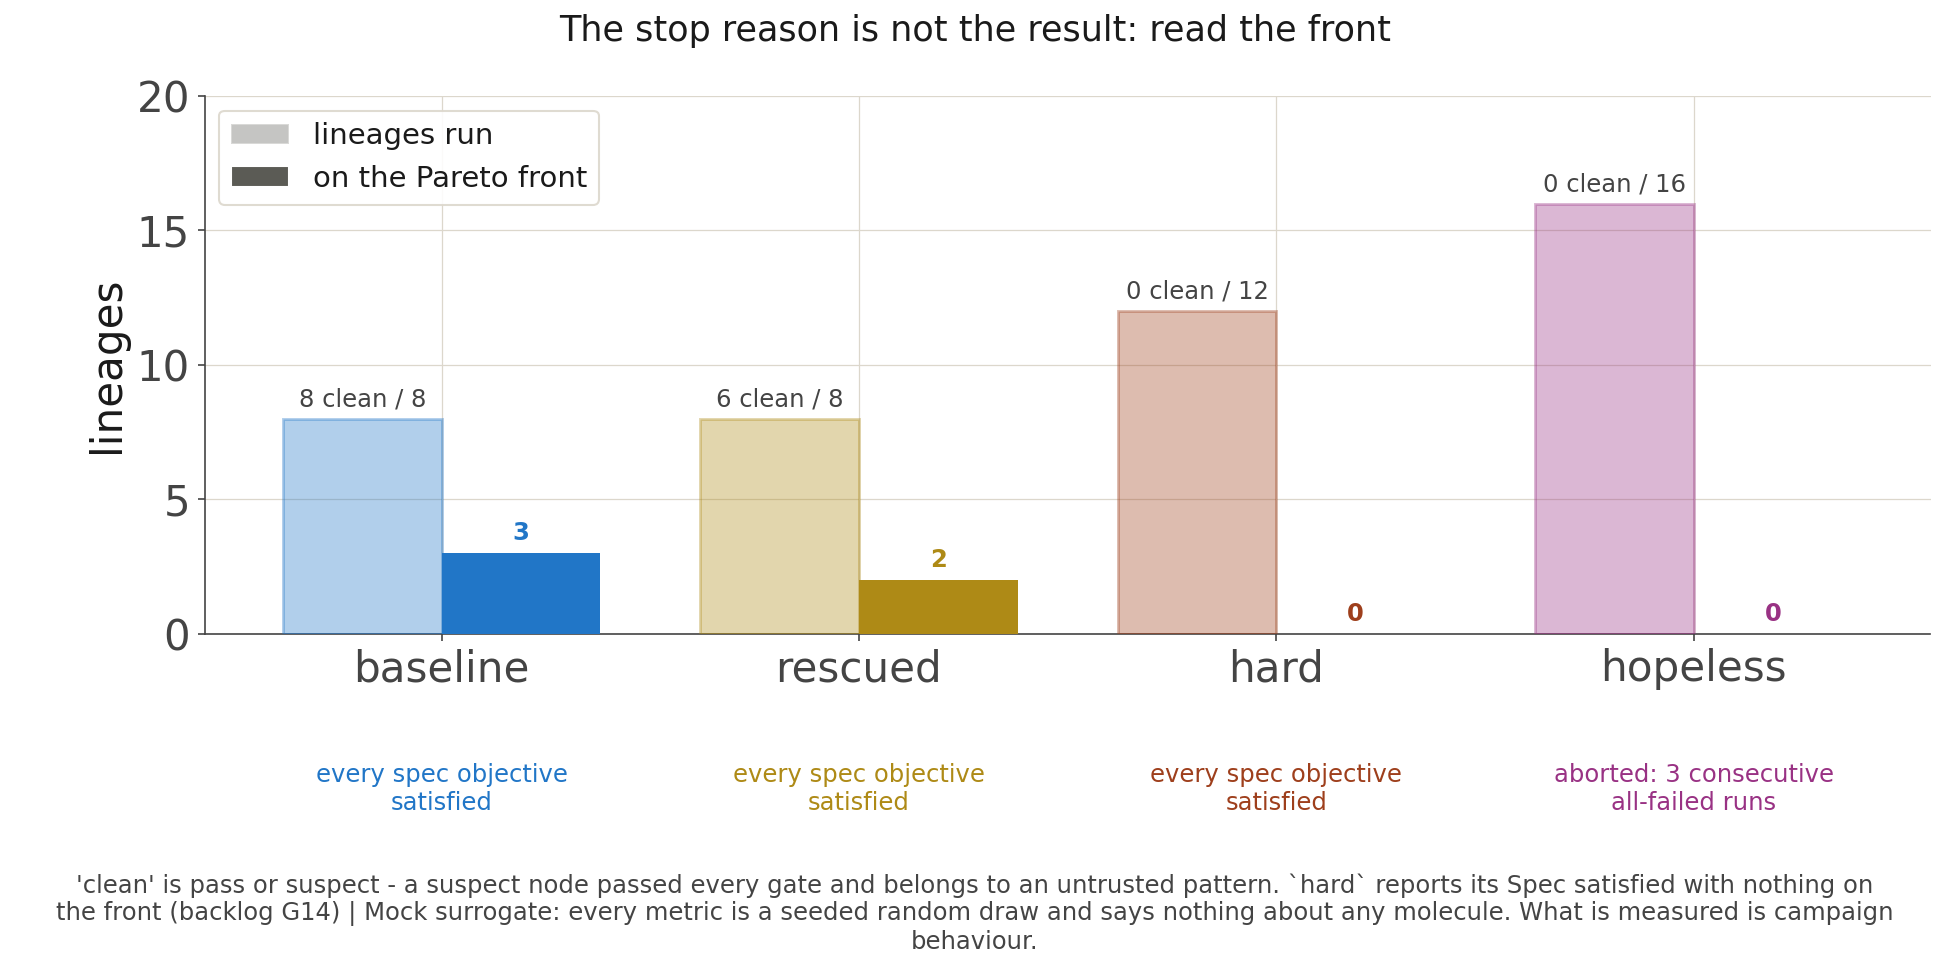

In [6]:
figures = {p.name.split("-")[0]: p for p in mock_figures.draw_all(LAB)}
# draw_all writes eleven figures and leaves them open; without this the inline
# backend attaches every one of them to this cell's output.
plt.close("all")

display(Image(str(figures["f6"]), width=900))

### Trap 1 -- the stop reason is not the result

Three of the four arms stop on **"every spec objective satisfied"**. Only two of
them have anything on the front. `hard` reports success with an empty front and
twelve failed lineages.

This is not an artefact of the surrogate. It is a real defect in the engine,
tracked as backlog **G14**, and it comes from two halves of "is this campaign
finished?" reading different evidence:

* `DataRegistry.ingest` records a task's metrics **whatever its QC verdict**,
  and `SatisfactionRule` counts those readings.
* `core/pareto` correctly refuses a FAILed node a place on the front.

So every objective has enough readings to look satisfied, while nothing has
actually passed. It is unfixed on purpose: changing what satisfaction counts
changes when the pre-registered campaigns stop.

The general lesson is the one worth carrying off this notebook. **An autonomous
system reporting that it is done is not evidence that it produced anything.**
The two have to be checked separately, which is why `f6` plots them against each
other.

## Two kinds of failing

Now the per-stage funnel. The failures are split into acceptance shortfalls and
integrity failures, and only one of those costs anything.

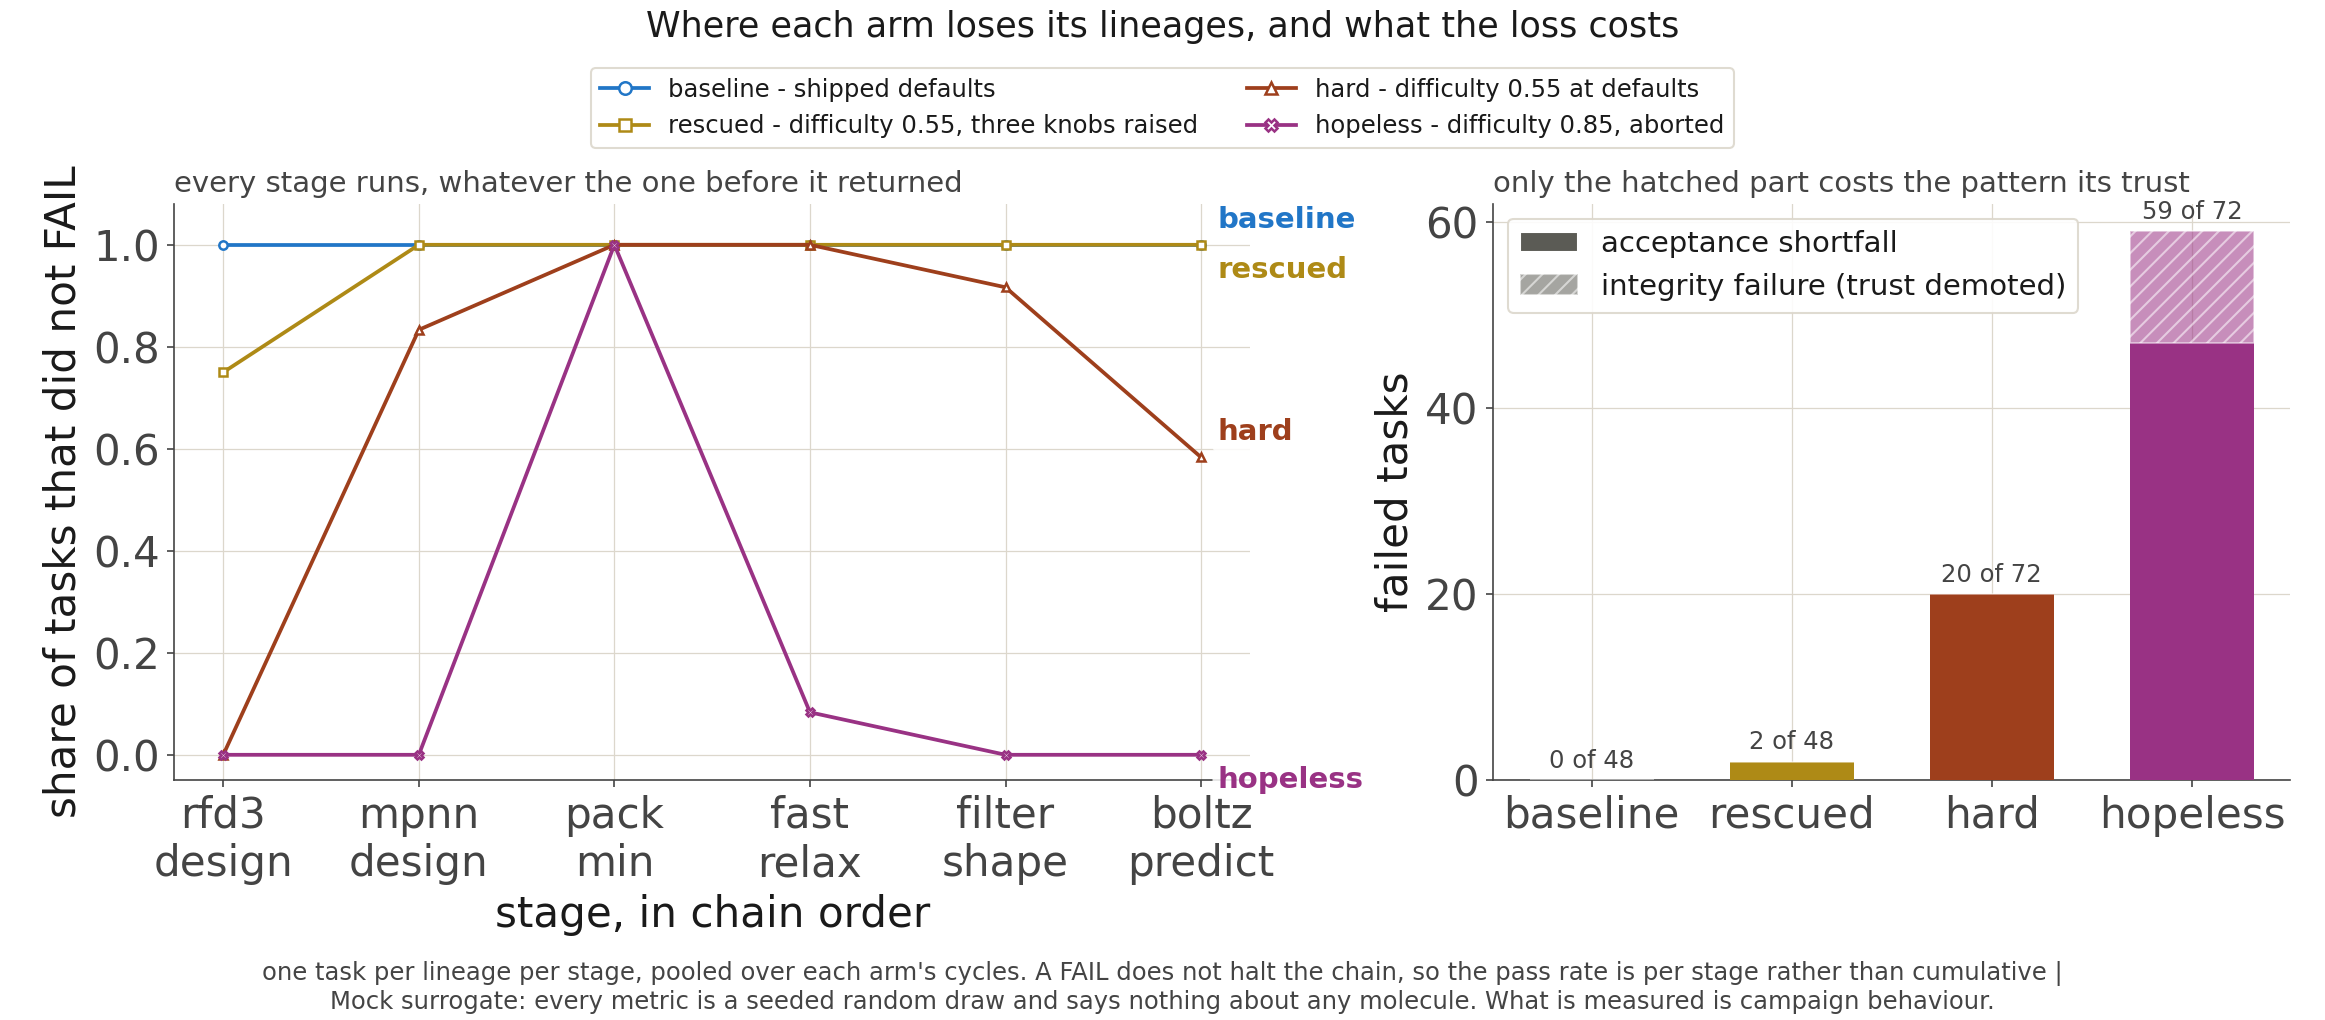

In [7]:
display(Image(str(figures["f3"]), width=900))

In [8]:
lineages = mock_lab.read_table(tables["lineages"])
rows = []
for arm in ARM_ORDER:
    sub = [r for r in lineages if r["arm"] == arm]
    rows.append({
        "arm": arm,
        "lineages": len(sub),
        "qc": dict(Counter(r["qc"] for r in sub)),
        "integrity failures": sum(1 for r in sub if r["failed_integrity"]),
        "acceptance failures": sum(1 for r in sub if r["failed_acceptance"]),
    })
show(rows, ["arm", "lineages", "qc", "integrity failures", "acceptance failures"])

arm       lineages  qc                         integrity failures  acceptance failures
--------  --------  -------------------------  ------------------  -------------------
baseline  8         {'suspect': 8}             0                   0                  
rescued   8         {'suspect': 6, 'fail': 2}  0                   2                  
hard      12        {'fail': 12}               0                   12                 
hopeless  16        {'fail': 16}               16                  16                 


### Trap 2 -- acceptance and integrity are not degrees of the same thing

`hard` and `hopeless` both fail every lineage. They are not the same failure.

* **`hard` (difficulty 0.55)** misses a quality bar. Every failure is an
  *acceptance* failure: the node FAILs, and the pattern's trust is untouched.
* **`hopeless` (difficulty 0.85)** drives `ss_fraction` under the
  `has_secondary_structure` floor. That is an *integrity* failure: the node
  FAILs **and** the pattern is demoted.

The line sits at roughly 0.75, and it is a threshold rather than a slope. This
is [decision 0013](../impress-a/decisions/0013-trust-counts-integrity-not-acceptance.md),
and it exists because counting quality thresholds against trust made promotion a
function of how hard the target was -- one real job ran 30 tasks clean and
promoted nothing.

Reaching for a dial to "make the campaign fail" without noticing which kind of
failure you bought is the mistake this toolkit exists to make visible.

## Now predict, then run

Set a difficulty and commit to a prediction **before** you run the next cell.
Saying it out loud is the exercise; the gap between what the campaign looks like
it should do and what it does is the thing being tested, not the numbers, which
are drawn.

In [9]:
difficulty = 0.55  # @param [0.25, 0.55, 0.85] {type:"raw"}
prediction = "it aborts"  # @param ["every spec objective satisfied", "it stops on stagnation", "it aborts"]

print(f"difficulty {difficulty}, and you predict: {prediction}")

difficulty 0.55, and you predict: it aborts


In [10]:
def one_campaign(name, params, lab, salt=None):
    """One campaign, isolated the way the lab isolates a cell."""
    overrides = {**mock_lab.LAB_BASE, **mock_lab.ARM_BASE}
    if params:
        overrides["params"] = params
    cell = mock_lab.Cell(
        cell=name, kind="arm", arm=name, knob="", value=0.0,
        salt=salt or name, rep=0, model="D", overrides=overrides,
    )
    record = mock_lab.run_cell(cell, yaml.safe_load(BASE_SPEC.read_text()), lab)
    # `collect` joins against the manifest that the full sweep writes. One cell run by
    # hand has no sweep behind it, so write the one record it needs.
    (lab / "manifest.json").write_text(
        json.dumps({"cells": [record], "disclaimer": mock_lab.DISCLAIMER}, default=str)
    )
    # `collect` logs a row count per table. Useful for a full lab, noise here.
    lab_log = logging.getLogger(mock_lab.__name__)
    lab_log.setLevel(logging.WARNING)
    try:
        tables = mock_lab.collect(lab)
    finally:
        lab_log.setLevel(logging.NOTSET)
    return [r for r in mock_lab.read_table(tables["campaigns"])
            if r["arm"] == name][0]


def verdict(stop_reason, aborted):
    if aborted or "aborted" in stop_reason:
        return "it aborts"
    if "stagnat" in stop_reason:
        return "it stops on stagnation"
    return "every spec objective satisfied"


BROKEN = pathlib.Path(tempfile.mkdtemp(prefix="knob-broken-"))
row = one_campaign("yours", {"mock_rfd3_design": {"difficulty": difficulty}}, BROKEN)

actual = verdict(row["stop_reason"], row["aborted"])
print()
print(f"  you said   {prediction}")
print(f"  it did     {actual}")
print(f"  cycles     {row['cycles']}")
print(f"  front      {row['front']}      <- designs that actually passed")
print(f"  stop       {row['stop_reason']}")
print()
print("  right" if actual == prediction else "  not what you predicted")

yours exit=0 in 2.0s


/tmp/knob-broken-n9selu12/tables/decisions.csv: no rows



  you said   it aborts
  it did     every spec objective satisfied
  cycles     2
  front      0      <- designs that actually passed
  stop       every spec objective satisfied

  not what you predicted


## Buy it back

Keep the difficulty where it is and raise three knobs: `diffusion_steps` to 200,
`packmin.cycles` to 5, and `diffusion_samples` to 25. This is the `rescued` arm,
and it is the matched partner of `hard`.

Which of the three did the work? `f2` has the spans.

In [11]:
RESCUE = pathlib.Path(tempfile.mkdtemp(prefix="knob-rescue-"))
rescued = one_campaign(
    "yours-rescued",
    {
        "mock_rfd3_design": {"difficulty": difficulty, "diffusion_steps": 200},
        "mock_packmin": {"cycles": 5},
        "mock_boltz_predict": {"diffusion_samples": 25},
    },
    RESCUE,
)
show([row, rescued], ["arm", "cycles", "front", "n_fail", "aborted", "stop_reason"])

yours-rescued exit=0 in 2.0s


/tmp/knob-rescue-ncvuhe0c/tables/decisions.csv: no rows


arm            cycles  front  n_fail  aborted  stop_reason                   
-------------  ------  -----  ------  -------  ------------------------------
yours          2       0      8       False    every spec objective satisfied
yours-rescued  2       4      4       False    every spec objective satisfied


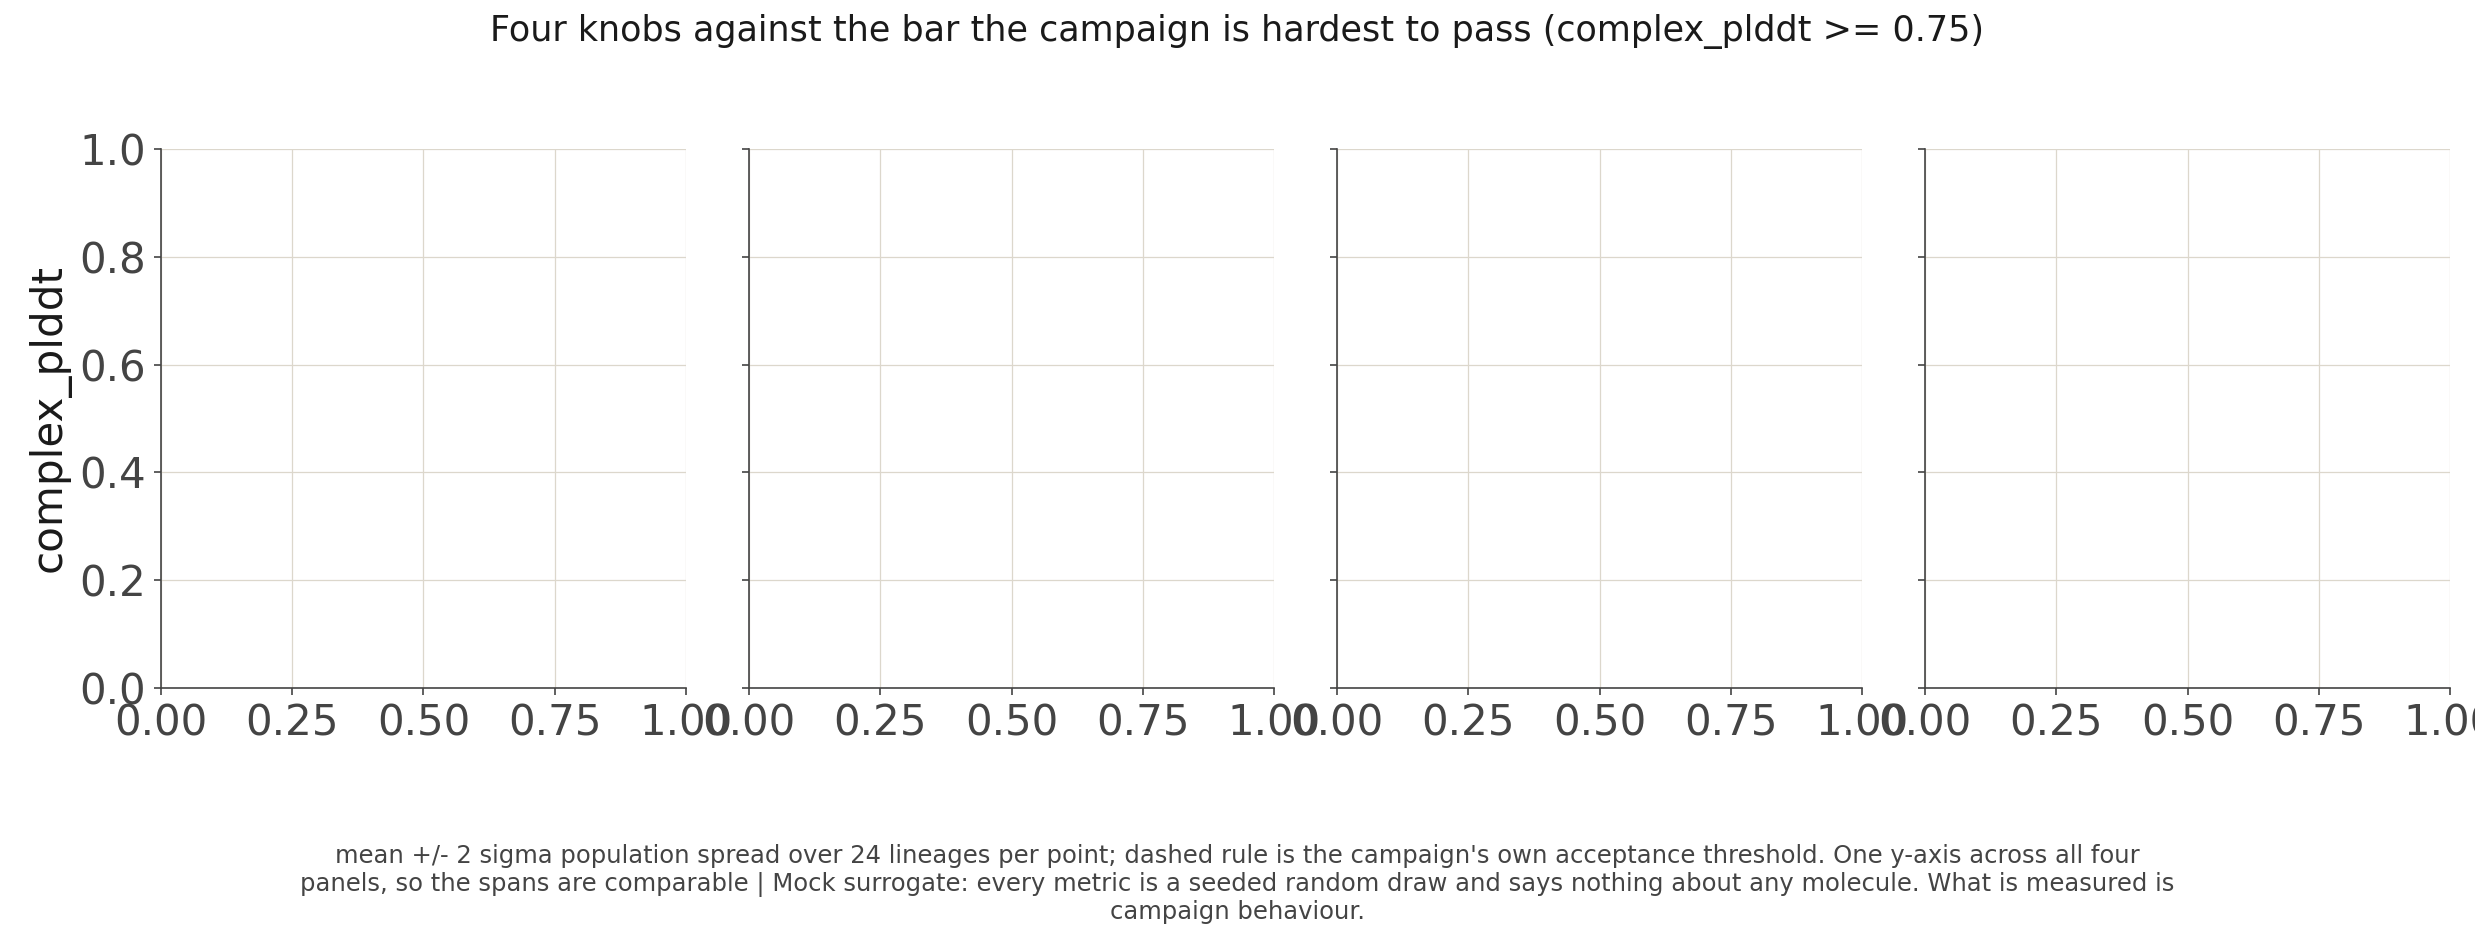

In [12]:
display(Image(str(figures["f2"]), width=900))

One honest caveat, measured from the arm's own `stages.jsonl` rather than
assumed: **two of those three knobs only hold for cycle 1.** From cycle 2 the
planner escalates `diffusion_steps` and `packmin.cycles` from the *tool spec's*
defaults and the policy wins the merge, so they end up below what the arm
declared. `diffusion_samples` survives, because it is a **breadth** knob no
planner may touch. The campaign is real and the measured behaviour is real; what
the label overstates is how much of it is held across cycles. Backlog G17.

## What you just ran, and what it did not include

Everything above used **model D** -- the deterministic control: rules end to end,
no language model, no network, no key. That is the reproducible baseline, and
it is what the sweeps always use.

The lab has a second axis this notebook does not turn. `--reasoners A` and `B`
replace the rules above the tools with a live model, and they need a profile in
`agent/models.yaml` naming an endpoint plus a key in its environment variable.
Two things are worth knowing before you reach for it:

* **The lab refuses a live model with no profile rather than quietly running the
  rehearsal.** `--model B` without one runs `RehearsalOracle` and reports zero
  LLM calls -- which is exactly what a *degraded* live arm reports. A figure
  labelled "model B" drawn from the rehearsal is a manufactured void outcome, so
  the lab exits 2 and names what it refused, before spending anything.
* **It probes the endpoint once before any live cell**, because a failure inside
  a campaign cycle is retried twice, recorded as `reasoner_degraded`, and then
  falls back to model D's cascade -- and the campaign exits 0. Without the probe
  you would get a full set of figures for a model that never answered.

There are no recorded LLM transcripts in this repository, so nothing here can
replay a live run offline. If you do run one, check `degraded_events` in
`campaigns.csv` before reading any of its yield.

## Three things to try

**Run the sweeps.** `mock_lab.sweep(LAB, repeats=1, only=["sweeps"])` walks five
knobs across their declared ranges, one cycle per cell, and `f1` and `f2` turn
into response surfaces. About a minute.

**Run an arm twice into the same trust directory.** Verdicts move, because the
pattern is already promoted the second time. This is why every cell above got
its own ledger.

**Set `tool_delivery: real` in the spec.** The campaign is refused at validation
rather than quietly reporting drawn numbers as science. That is gate 6, and it
is the interesting mistake to make on purpose.

## Where to go next

* [The Mock Knob Lab](../impress-a/reference/mock-lab.md) -- the harness: every arm, every swept knob, all eleven figures, and the three defects it found.
* [Architecture](../impress-a/reference/architecture.md) -- the outer loop, the layers and the invariants.
* [Control Models](../impress-a/reference/control-models.md) -- what each of A, B, C and D is shown and what it may choose.
* [Decision 0013](../impress-a/decisions/0013-trust-counts-integrity-not-acceptance.md) -- trap 2, argued at length.
* [Known Limitations](../impress-a/limitations.md) -- including the ones this notebook walked you into.
* [Small Molecule Binding](../examples/small-molecule-binding.md) -- the real chain these six surrogates stand in for.